In [2]:
%matplotlib inline

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from scipy.interpolate import RegularGridInterpolator

plt.rcParams.update(
    {
        'font.family': 'serif',
        'font.serif': ['Times New Roman', 'DejaVu Serif'],
        'mathtext.fontset': 'stix',
        'font.size': 10,
        'axes.labelsize': 11,
        'axes.titlesize': 9,
        'xtick.labelsize': 9,
        'ytick.labelsize': 9,
        'legend.fontsize': 8.5,
        'axes.linewidth': 0.9,
        'axes.grid': False,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'xtick.top': True,
        'ytick.right': True,
        'xtick.major.size': 4.0,
        'ytick.major.size': 4.0,
        'xtick.minor.size': 2.2,
        'ytick.minor.size': 2.2,
        'xtick.minor.visible': True,
        'ytick.minor.visible': True,
        'legend.frameon': False,
        'figure.dpi': 150,
        'savefig.dpi': 300,
        'savefig.bbox': 'tight',
    }
)

CMAP_FLOW = 'RdBu_r'
C_RED = '#cc0000'
C_BLUE = '#0000dd'
C_GRAY = '0.72'

REPO_ROOT = next(q for q in [Path.cwd(), *Path.cwd().parents] if (q / 'pyproject.toml').exists())
DATA_ROOT = REPO_ROOT / 'data'
# 每次修改该名称
CASE_NAME = '3D-7-cyc-urans-tfbf'
CASE = DATA_ROOT / CASE_NAME
FIGDIR = REPO_ROOT / 'results' / CASE_NAME
FIGDIR.mkdir(parents=True, exist_ok=True)


def save_show(fig, name):
    fig.savefig(FIGDIR / name)
    plt.show()
    print(FIGDIR / name)


print(f'repo  : {REPO_ROOT}')
print(f'cases : {[q.name for q in sorted(DATA_ROOT.glob("3D-*"))]}')
print(f'case  : {CASE}')
print(f'figs  : {FIGDIR}')


repo  : c:\Users\Administrator\Desktop\PurineCFD-Plugin
cases : ['3D-1-cylinder-Re1000', '3D-2-cyc-lusgs', '3D-3-cyc-lusgs', '3D-4-cyc-urans', '3D-5-cyc-urans', '3D-6-cyc-urans-i20', '3D-7-cyc-urans-tfbf']
case  : c:\Users\Administrator\Desktop\PurineCFD-Plugin\data\3D-7-cyc-urans-tfbf
figs  : c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf


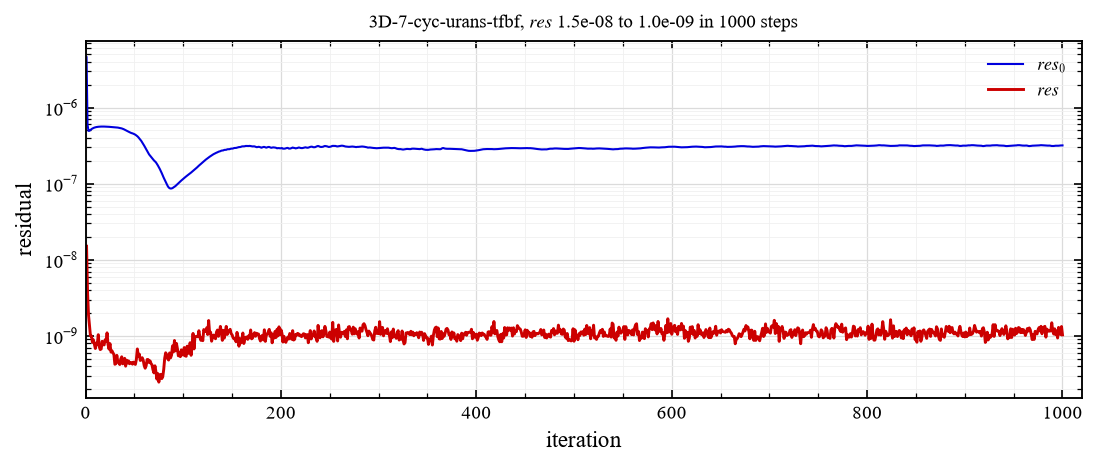

c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\residual.png


In [3]:
hist = pd.read_csv(CASE / 'history.csv')
has_phase = 'phase' in hist.columns
has_inner = 'res0' in hist.columns and 'inner' in hist.columns

if has_phase:
    steady = hist[hist['phase'] == 'S']
    urans = hist[hist['phase'] == 'U']
else:
    steady = hist.iloc[:0]
    urans = hist

n_offset = int(steady['step'].max()) if len(steady) else 0
iter_steady = steady['step'].to_numpy(float)
iter_urans = urans['step'].to_numpy(float) + n_offset
iteration = np.concatenate((iter_steady, iter_urans))

fig, ax = plt.subplots(figsize=(7.2, 3.0), layout='constrained')
if has_inner:
    ax.semilogy(
        iteration,
        np.concatenate((steady['res0'], urans['res0'])),
        color=C_BLUE,
        linewidth=1.0,
        label=r'$res_0$',
    )
ax.semilogy(
    iteration,
    np.concatenate((steady['res'], urans['res'])),
    color=C_RED,
    linewidth=1.4,
    label=r'$res$',
)
if len(steady):
    ax.axvline(n_offset, color='0.45', linewidth=0.8, linestyle='--')
    ax.text(n_offset * 0.5, 0.55, 'steady', transform=ax.get_xaxis_transform(), ha='center', color='0.35')
    ax.text(n_offset * 1.5, 0.55, 'URANS', transform=ax.get_xaxis_transform(), ha='center', color='0.35')
ax.set_xlabel('iteration')
ax.set_ylabel('residual')
ax.set_title(
    f'{CASE_NAME}, $res$ {urans["res"].iloc[0]:.1e} to {urans["res"].iloc[-1]:.1e} in {urans.shape[0]} steps'
)
ax.set_xlim(0.0, float(iteration.max()) * 1.02)
ax.grid(True, which='major', color='0.86', linewidth=0.6)
ax.grid(True, which='minor', color='0.94', linewidth=0.4)
ax.legend(loc='upper right')
save_show(fig, 'residual.png')


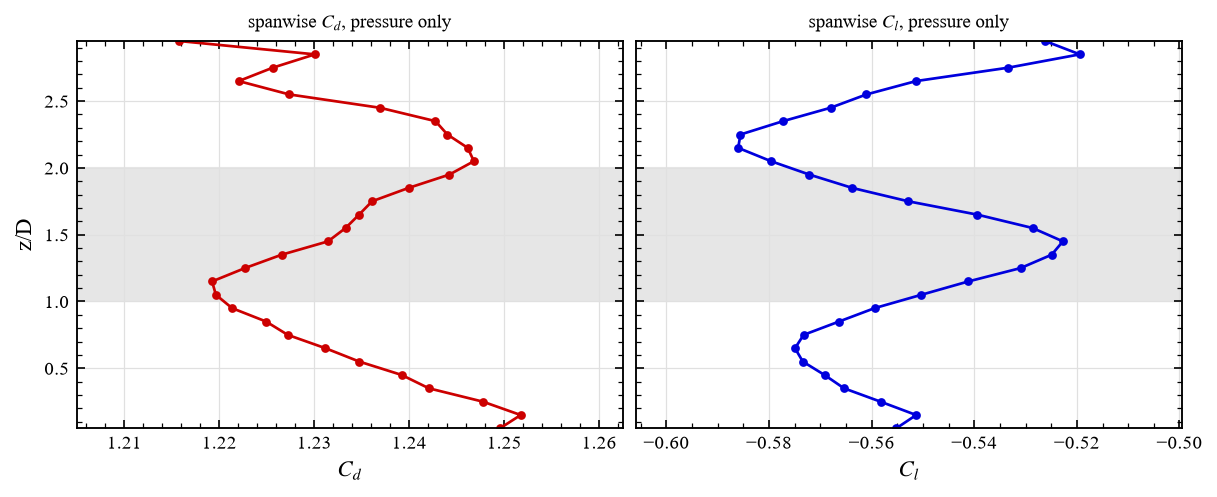

c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\force_spanwise.png


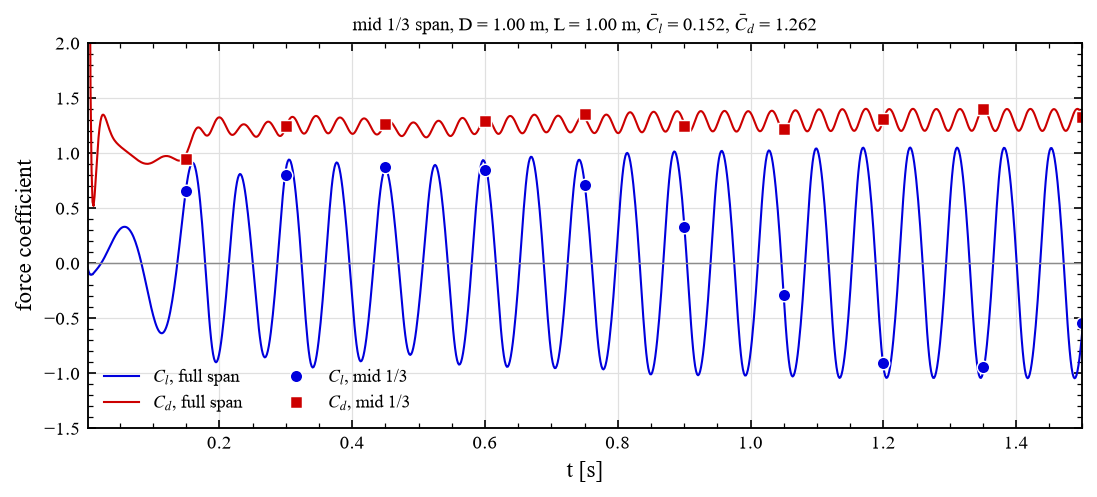

c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\force_history.png
D = 0.9995 m, span = 3.0000 m, mid third = [1.000, 2.000], L = 1.0000 m
mid planes = 10 of 30
wall C_d per plane = 1.2158 ... 1.2517, mid mean = 1.2308
wall C_l per plane = -0.5860 ... -0.5194, mid mean = -0.5427
snapshots used = 10
friction offset Cd_hist - Cd_pressure = 0.0762 ... 0.1045
negative offsets clipped to zero: 0 of 10
 step   time  cd_mid  cl_mid  cd_full  cl_full  friction  friction_used  cd_mid_total
  100 0.1500  0.8678  0.6513   0.9149   0.6630    0.0762         0.0762        0.9440
  200 0.3000  1.1568  0.7987   1.1412   0.8221    0.0918         0.0918        1.2486
  300 0.4500  1.1708  0.8720   1.1704   0.8160    0.0961         0.0961        1.2669
  400 0.6000  1.1944  0.8429   1.2210   0.8703    0.0991         0.0991        1.2935
  500 0.7500  1.2579  0.7125   1.2188   0.6882    0.1015         0.1015        1.3595
  600 0.9000  1.1480  0.3249   1.1707   0.3281    0.1014 

In [4]:
wall = pd.read_csv(CASE / 'wall_cp.csv')
z_wall = np.unique(wall['z'].to_numpy())
n_theta = int(wall.shape[0] // z_wall.size)
dtheta = 2.0 * np.pi / n_theta
radius = float(np.median(np.hypot(wall['x'], wall['y'])))
diam = 2.0 * radius
dz_wall = float(np.median(np.diff(z_wall)))
z_low_edge = float(z_wall.min() - 0.5 * dz_wall)
z_high_edge = float(z_wall.max() + 0.5 * dz_wall)
span = z_high_edge - z_low_edge
mid_lo = float(z_low_edge + span / 3.0)
mid_hi = float(z_high_edge - span / 3.0)
seg_length = mid_hi - mid_lo
in_mid = (z_wall >= mid_lo - 1e-9) & (z_wall <= mid_hi + 1e-9)

cp_wall = wall['cp'].to_numpy().reshape(z_wall.size, n_theta)
th_wall = np.arctan2(wall['y'].to_numpy(), wall['x'].to_numpy()).reshape(z_wall.size, n_theta)
cd_plane = -(cp_wall * np.cos(th_wall)).sum(axis=1) * radius * dtheta / diam
cl_plane = -(cp_wall * np.sin(th_wall)).sum(axis=1) * radius * dtheta / diam

fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.2), layout='constrained', sharey=True)
axes[0].axhspan(mid_lo, mid_hi, color='0.90', zorder=0)
axes[0].plot(cd_plane, z_wall, color=C_RED, linewidth=1.3, marker='o', markersize=3.2)
axes[0].set_xlabel(r'$C_d$')
axes[0].set_ylabel('z/D')
axes[0].set_title('spanwise $C_d$, pressure only')
axes[1].axhspan(mid_lo, mid_hi, color='0.90', zorder=0)
axes[1].plot(cl_plane, z_wall, color=C_BLUE, linewidth=1.3, marker='o', markersize=3.2)
axes[1].set_xlabel(r'$C_l$')
axes[1].set_title('spanwise $C_l$, pressure only')
axes[0].set_xlim(cd_plane.min() - 0.3 * np.ptp(cd_plane), cd_plane.max() + 0.3 * np.ptp(cd_plane))
axes[1].set_xlim(cl_plane.min() - 0.3 * np.ptp(cl_plane), cl_plane.max() + 0.3 * np.ptp(cl_plane))
for ax in axes:
    ax.set_ylim(z_wall.min(), z_wall.max())
    ax.grid(True, which='major', color='0.88', linewidth=0.6)
save_show(fig, 'force_spanwise.png')

snapshots = sorted(CASE.glob('field_[0-9][0-9][0-9][0-9][0-9].csv'))
if not snapshots and (CASE / 'field.csv').exists():
    snapshots = [CASE / 'field.csv']
snapshots = [p for p in snapshots if p.exists()]

time_axis = None
if 'time' in hist.columns and urans['time'].nunique() > 1:
    time_axis = urans.groupby('step')['time'].first()

rows = []
cp_curves = []
ref = None
for path in snapshots:
    field_snap = pd.read_csv(path)
    xs = field_snap['x'].to_numpy()
    ys = field_snap['y'].to_numpy()
    zs = field_snap['z'].to_numpy()
    ps = field_snap['p'].to_numpy()
    rs = np.hypot(xs, ys)
    ts = np.arctan2(ys, xs)
    far_snap = rs > 0.7 * rs.max()
    p_ref = float(np.median(ps[far_snap]))
    rho_ref = float(np.median(field_snap['rho'].to_numpy()[far_snap]))
    u_ref = float(np.median(field_snap['u'].to_numpy()[far_snap]))
    q_ref = 0.5 * rho_ref * u_ref ** 2
    ref = {'p_inf': p_ref, 'rho_inf': rho_ref, 'u_inf': u_ref, 'q_inf': q_ref}

    inner_snap = np.isclose(rs, rs.min())
    z_snap = np.unique(zs[inner_snap])
    cp_snap = ((ps[inner_snap] - p_ref) / q_ref).reshape(z_snap.size, n_theta)
    th_snap = ts[inner_snap].reshape(z_snap.size, n_theta)
    dz_snap = float(np.median(np.diff(z_snap)))
    snap_lo_edge = float(z_snap.min() - 0.5 * dz_snap)
    snap_hi_edge = float(z_snap.max() + 0.5 * dz_snap)
    span_snap = snap_hi_edge - snap_lo_edge
    mid_snap = (z_snap >= snap_lo_edge + span_snap / 3.0 - 1e-9) & (
        z_snap <= snap_hi_edge - span_snap / 3.0 + 1e-9
    )

    cd_all = -(cp_snap * np.cos(th_snap)).sum(axis=1) * radius * dtheta / diam
    cl_all = -(cp_snap * np.sin(th_snap)).sum(axis=1) * radius * dtheta / diam

    digits = [int(q) for q in path.stem.split('_')[1:] if q.isdigit()]
    step_val = digits[0] if digits else int(hist['step'].max())
    if time_axis is not None and step_val in time_axis.index:
        time_val = float(time_axis.loc[step_val])
    else:
        time_val = float(step_val)

    cd_hist = float(urans.loc[urans['step'] == step_val, 'cd'].iloc[-1])
    friction = cd_hist - float(cd_all.mean())
    rows.append(
        {
            'step': step_val,
            'time': time_val,
            'cd_mid': float(cd_all[mid_snap].mean()),
            'cl_mid': float(cl_all[mid_snap].mean()),
            'cd_full': float(cd_all.mean()),
            'cl_full': float(cl_all.mean()),
            'friction': friction,
        }
    )
    tag = f't = {time_val:.3f} s' if time_axis is not None else f'step {step_val}'
    cp_curves.append((tag, cp_snap[mid_snap].mean(axis=0), th_snap[0]))

force = pd.DataFrame(rows).sort_values('time').reset_index(drop=True)
force['friction_used'] = force['friction'].clip(lower=0.0)
force['cd_mid_total'] = force['cd_mid'] + force['friction_used']

if time_axis is not None:
    curve_x = urans['time'].to_numpy(float)
    x_label = 't [s]'
else:
    curve_x = urans['step'].to_numpy(float)
    x_label = 'iteration'

fig, ax = plt.subplots(figsize=(7.2, 3.2), layout='constrained')
ax.plot(curve_x, urans['cl'].to_numpy(float), color=C_BLUE, linewidth=1.0, label=r'$C_l$, full span')
ax.plot(curve_x, urans['cd'].to_numpy(float), color=C_RED, linewidth=1.0, label=r'$C_d$, full span')
ax.plot(
    force['time'],
    force['cl_mid'],
    linestyle='none',
    marker='o',
    markersize=6.0,
    color=C_BLUE,
    markeredgecolor='w',
    markeredgewidth=0.7,
    label=r'$C_l$, mid 1/3',
)
ax.plot(
    force['time'],
    force['cd_mid_total'],
    linestyle='none',
    marker='s',
    markersize=6.0,
    color=C_RED,
    markeredgecolor='w',
    markeredgewidth=0.7,
    label=r'$C_d$, mid 1/3',
)
ax.axhline(0.0, color='0.55', linewidth=0.7)
ax.set_xlabel(x_label)
ax.set_ylabel('force coefficient')
ax.set_title(
    f'mid 1/3 span, D = {diam:.2f} m, L = {seg_length:.2f} m, '
    f'$\\bar{{C}}_l$ = {force["cl_mid"].mean():.3f}, $\\bar{{C}}_d$ = {force["cd_mid_total"].mean():.3f}'
)
ax.set_xlim(float(curve_x.min()), float(curve_x.max()))
ax.set_ylim(-1.5, 2)
ax.grid(True, which='major', color='0.88', linewidth=0.6)
ax.legend(loc='lower left', ncol=2)
save_show(fig, 'force_history.png')

print(f'D = {diam:.4f} m, span = {span:.4f} m, mid third = [{mid_lo:.3f}, {mid_hi:.3f}], L = {seg_length:.4f} m')
print(f'mid planes = {int(in_mid.sum())} of {z_wall.size}')
print(f'wall C_d per plane = {cd_plane.min():.4f} ... {cd_plane.max():.4f}, mid mean = {cd_plane[in_mid].mean():.4f}')
print(f'wall C_l per plane = {cl_plane.min():.4f} ... {cl_plane.max():.4f}, mid mean = {cl_plane[in_mid].mean():.4f}')
print(f'snapshots used = {len(snapshots)}')
print(f'friction offset Cd_hist - Cd_pressure = {force["friction"].min():.4f} ... {force["friction"].max():.4f}')
print(f'negative offsets clipped to zero: {int((force["friction"] < 0).sum())} of {len(force)}')
print(force.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

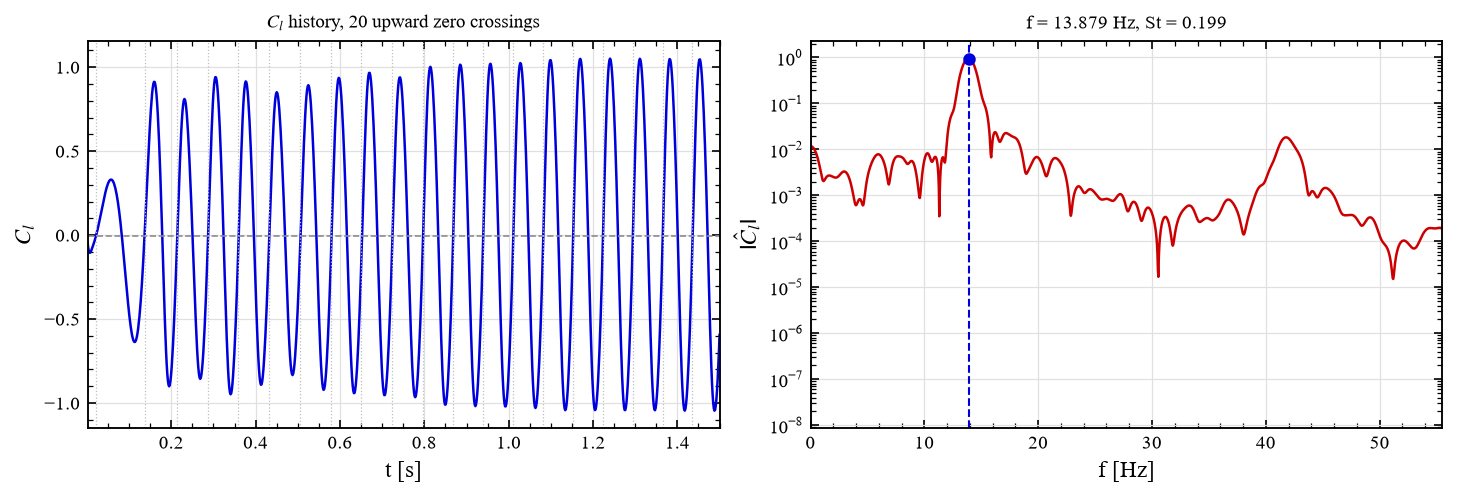

c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\cl_spectrum.png
samples = 1000, dt = 0.00150 s, fs = 666.67 Hz, raw df = 0.667 Hz
window = 0.0015 ... 1.5000 s
dominant frequency (FFT peak) = 13.8794 Hz
dominant frequency (zero crossing) = 13.4323 Hz
zero-crossing periods = [0.1155 0.0765 0.0735 0.072  0.0735 0.0735 0.0735 0.072  0.0735 0.072
 0.072  0.0705 0.072  0.0705 0.0705 0.0705 0.072  0.0705 0.0705]
D = 0.9995 m, U_inf = 69.6232 m/s
St (FFT peak) = 0.1993
St (zero crossing) = 0.1928
St from last period = 0.2036
frequency resolution = +/-0.333 Hz, St resolution = +/-0.0048


In [5]:
has_time = time_axis is not None and ref is not None

if not has_time:
    print('time or far-field reference unavailable, spectral analysis and St are skipped')
else:
    cl_sig = urans['cl'].to_numpy(float)
    t_sig = urans['time'].to_numpy(float)
    dt_sig = float(np.median(np.diff(t_sig)))
    fs_sig = 1.0 / dt_sig
    n_samp = cl_sig.size
    df_raw = fs_sig / n_samp
    sig = cl_sig - cl_sig.mean()
    window = np.hanning(n_samp)
    n_fft = 1 << int(np.ceil(np.log2(n_samp * 16)))
    spectrum = np.abs(np.fft.rfft(sig * window, n_fft)) * 2.0 / window.sum()
    freq = np.fft.rfftfreq(n_fft, dt_sig)

    k_peak = int(np.argmax(spectrum[1:])) + 1
    y0, y1, y2 = np.log(spectrum[k_peak - 1 : k_peak + 2])
    delta = 0.5 * (y0 - y2) / (y0 - 2.0 * y1 + y2) if np.isfinite(y0 + y2) else 0.0
    f_peak = float(freq[k_peak] + delta * freq[1])

    zero_up = np.flatnonzero((sig[:-1] <= 0.0) & (sig[1:] > 0.0))
    periods = np.diff(t_sig[zero_up])
    f_zero = float(1.0 / periods.mean()) if periods.size > 1 else np.nan

    u_inf = float(ref['u_inf'])
    st_peak = f_peak * diam / u_inf
    st_zero = f_zero * diam / u_inf

    fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.2), layout='constrained')
    axes[0].plot(t_sig, cl_sig, color=C_BLUE, linewidth=1.2)
    axes[0].axhline(cl_sig.mean(), color='0.55', linewidth=0.8, linestyle='--')
    for tz in t_sig[zero_up]:
        axes[0].axvline(tz, color='0.75', linewidth=0.6, linestyle=':')
    axes[0].set_xlabel('t [s]')
    axes[0].set_ylabel(r'$C_l$')
    axes[0].set_title(f'$C_l$ history, {zero_up.size} upward zero crossings')
    axes[0].set_xlim(float(t_sig.min()), float(t_sig.max()))
    axes[0].grid(True, which='major', color='0.88', linewidth=0.6)

    axes[1].semilogy(freq, spectrum, color=C_RED, linewidth=1.2)
    axes[1].axvline(f_peak, color=C_BLUE, linewidth=1.0, linestyle='--')
    axes[1].plot([f_peak], [spectrum[k_peak]], marker='o', color=C_BLUE, markersize=5.0, linestyle='none')
    axes[1].set_xlabel('f [Hz]')
    axes[1].set_ylabel(r'$|\hat{C}_l|$')
    axes[1].set_title(f'f = {f_peak:.3f} Hz, St = {st_peak:.3f}')
    axes[1].set_xlim(0.0, 4.0 * f_peak)
    axes[1].grid(True, which='major', color='0.88', linewidth=0.6)
    save_show(fig, 'cl_spectrum.png')

    print(f'samples = {n_samp}, dt = {dt_sig:.5f} s, fs = {fs_sig:.2f} Hz, raw df = {df_raw:.3f} Hz')
    print(f'window = {t_sig[0]:.4f} ... {t_sig[-1]:.4f} s')
    print(f'dominant frequency (FFT peak) = {f_peak:.4f} Hz')
    print(f'dominant frequency (zero crossing) = {f_zero:.4f} Hz')
    print(f'zero-crossing periods = {np.round(periods, 4)}')
    print(f'D = {diam:.4f} m, U_inf = {u_inf:.4f} m/s')
    print(f'St (FFT peak) = {st_peak:.4f}')
    print(f'St (zero crossing) = {st_zero:.4f}')
    print(f'St from last period = {diam / u_inf / periods[-1]:.4f}')
    print(
        f'frequency resolution = +/-{0.5 * df_raw:.3f} Hz, '
        f'St resolution = +/-{0.5 * df_raw * diam / u_inf:.4f}'
    )

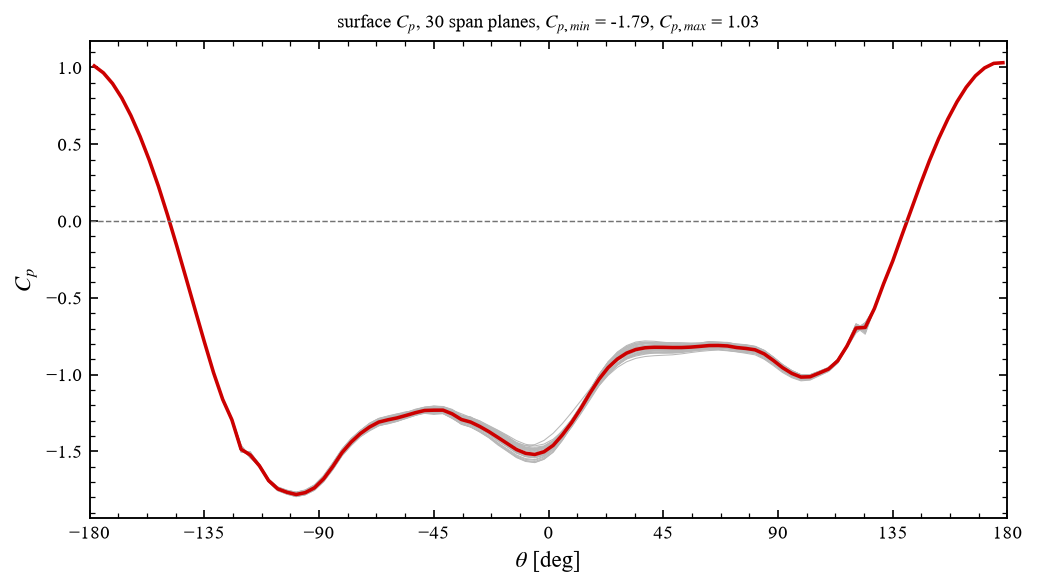

c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\cp_surface.png


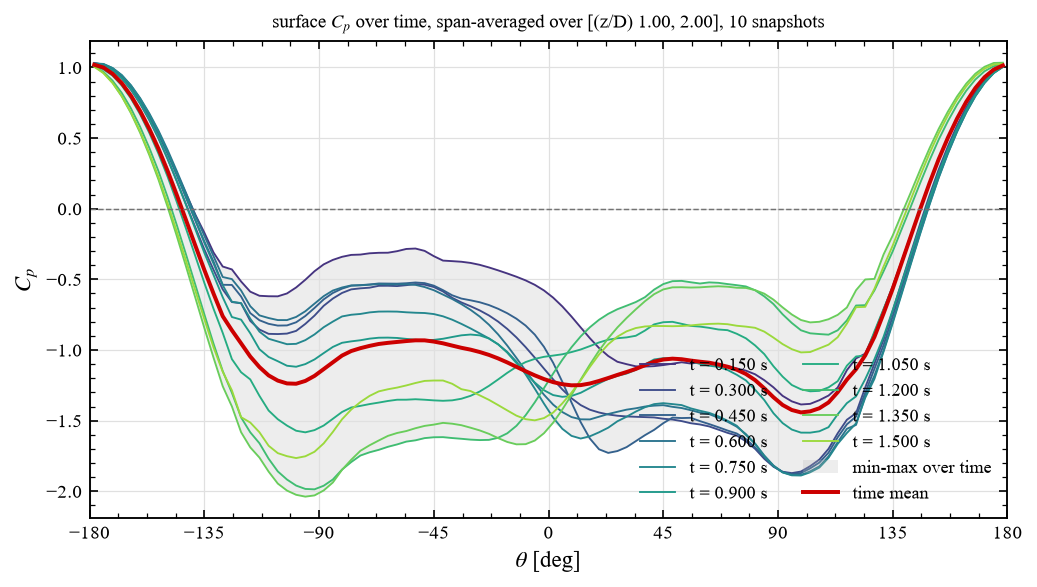

c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\cp_surface_time.png
Cp time-mean: min = -1.4417 at theta = 99.0 deg
Cp time-mean: max = 1.0192 at theta = -178.2 deg
Cp time range at theta = 0 deg: -1.5891 ... -0.5785
Cp spanwise spread at single time = 0.1236


In [6]:
theta_deg = np.degrees(th_wall[0])
order = np.argsort(theta_deg)
theta_axis = theta_deg[order]
cp_plane_sorted = cp_wall[:, order]

fig, ax = plt.subplots(figsize=(6.8, 3.8), layout='constrained')
for k in range(z_wall.size):
    ax.plot(theta_axis, cp_plane_sorted[k], color=C_GRAY, linewidth=0.5)
ax.plot(theta_axis, cp_wall[:, order].mean(axis=0), color=C_RED, linewidth=1.7)
ax.axhline(0.0, color='0.45', linewidth=0.7, linestyle='--')
ax.set_xlabel(r'$\theta$ [deg]')
ax.set_ylabel(r'$C_p$')
ax.set_title(
    f'surface $C_p$, {z_wall.size} span planes, '
    f'$C_{{p,min}}$ = {cp_wall.min():.2f}, $C_{{p,max}}$ = {cp_wall.max():.2f}'
)
ax.set_xlim(-180.0, 180.0)
ax.set_xticks(np.arange(-180, 181, 45))
save_show(fig, 'cp_surface.png')

cp_time = np.array([curve[1][order] for curve in cp_curves])
cp_mean = cp_time.mean(axis=0)
time_labels = [curve[0] for curve in cp_curves]

fig, ax = plt.subplots(figsize=(6.8, 3.8), layout='constrained')
colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(cp_curves)))
for k, curve in enumerate(cp_curves):
    ax.plot(theta_axis, cp_time[k], color=colors[k], linewidth=0.9, label=time_labels[k])
ax.fill_between(
    theta_axis,
    cp_time.min(axis=0),
    cp_time.max(axis=0),
    color=C_GRAY,
    alpha=0.25,
    linewidth=0,
    label='min-max over time',
)
ax.plot(theta_axis, cp_mean, color=C_RED, linewidth=1.9, label='time mean')
ax.axhline(0.0, color='0.45', linewidth=0.7, linestyle='--')
ax.set_xlabel(r'$\theta$ [deg]')
ax.set_ylabel(r'$C_p$')
ax.set_title(
    f'surface $C_p$ over time, span-averaged over [(z/D) {mid_lo:.2f}, {mid_hi:.2f}], '
    f'{len(cp_curves)} snapshots'
)
ax.set_xlim(-180.0, 180.0)
ax.set_xticks(np.arange(-180, 181, 45))
ax.grid(True, which='major', color='0.88', linewidth=0.6)
ax.legend(loc='lower right', ncol=2)
save_show(fig, 'cp_surface_time.png')

peak = np.argmin(cp_mean)
print(f'Cp time-mean: min = {cp_mean.min():.4f} at theta = {theta_axis[peak]:.1f} deg')
print(f'Cp time-mean: max = {cp_mean.max():.4f} at theta = {theta_axis[np.argmax(cp_mean)]:.1f} deg')
print(f'Cp time range at theta = 0 deg: {cp_time[:, np.argmin(np.abs(theta_axis))].min():.4f} ... {cp_time[:, np.argmin(np.abs(theta_axis))].max():.4f}')
print(f'Cp spanwise spread at single time = {np.ptp(cp_wall, axis=0).max():.4f}')

In [7]:
field = pd.read_csv(CASE / 'field.csv')
xf = field['x'].to_numpy()
yf = field['y'].to_numpy()
zf = field['z'].to_numpy()
uf = field['u'].to_numpy()
vf = field['v'].to_numpy()
wf = field['w'].to_numpy()
rf = np.hypot(xf, yf)

far = rf > 0.7 * rf.max()
rho_inf = float(np.median(field['rho'].to_numpy()[far]))
p_inf = float(np.median(field['p'].to_numpy()[far]))
u_inf = float(np.median(uf[far]))
q_inf = 0.5 * rho_inf * u_inf ** 2
diam = 2.0 * float(rf.min())

z_planes = np.unique(zf)
first_plane = np.isclose(zf, z_planes[0])
theta_first = np.round(np.degrees(np.arctan2(yf[first_plane], xf[first_plane])), 4)
n_t = np.unique(theta_first).size
n_r = int(first_plane.sum() // n_t)
z_mid = 0.5 * (z_planes.min() + z_planes.max())
mid_index = np.argsort(np.abs(z_planes - z_mid))[:2]

sec_low = np.isclose(zf, z_planes[mid_index[0]])
sec_high = np.isclose(zf, z_planes[mid_index[1]])
x_sec = xf[sec_low]
y_sec = yf[sec_low]
u_sec = 0.5 * (uf[sec_low] + uf[sec_high])
v_sec = 0.5 * (vf[sec_low] + vf[sec_high])

print(f'field nodes = {xf.size}')
print(f'planes = {z_planes.size}, radial = {n_r}, tangential = {n_t}')
print(f'z/D = {z_planes.min():.3f} ... {z_planes.max():.3f}, mid-span = {z_mid:.3f}')
print(f'section from z/D = {z_planes[mid_index[0]]:.3f} and {z_planes[mid_index[1]]:.3f}')
print(f'D = {diam:.4f} m, rho_inf = {rho_inf:.4e} kg/m3, U_inf = {u_inf:.3f} m/s')
print(f'p_inf = {p_inf:.4f} Pa, q_inf = {q_inf:.6f} Pa')

param_file = CASE / 'parameters.json'
if param_file.exists():
    params = json.loads(param_file.read_text(encoding='utf-8'))
    print(
        f"parameters.json: Ma = {params['Ma']}, Re = {params['Re']}, "
        f"span = {params['span_length_D']} D, span boundary = {params['span_boundary']}"
    )

field nodes = 240000
planes = 30, radial = 80, tangential = 100
z/D = 0.050 ... 2.950, mid-span = 1.500
section from z/D = 1.550 and 1.450
D = 1.0196 m, rho_inf = 2.6593e-04 kg/m3, U_inf = 69.623 m/s
p_inf = 22.9002 Pa, q_inf = 0.644522 Pa


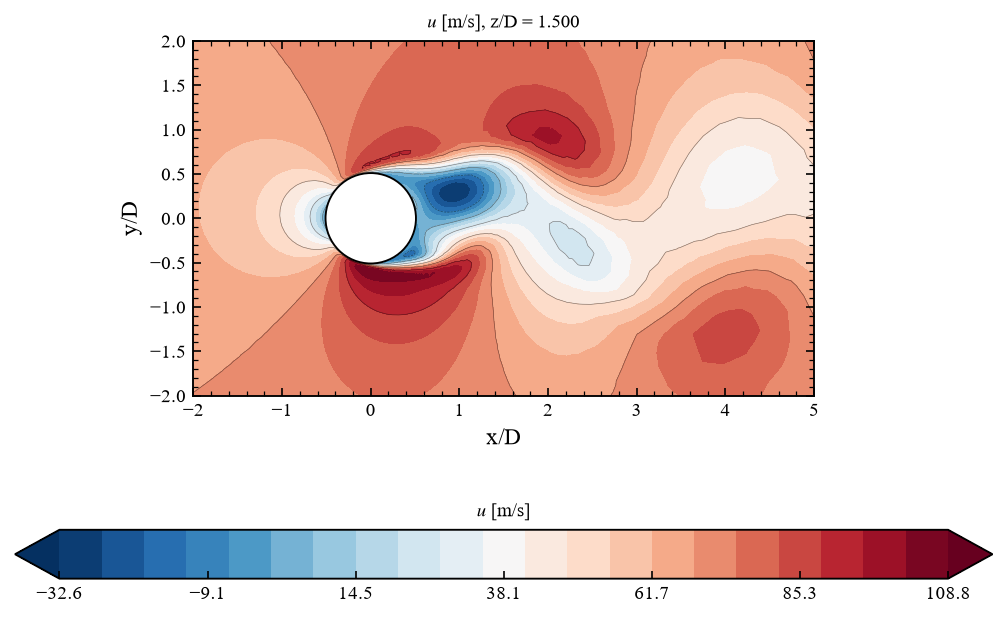

c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\u_section.png
$u$ [m/s]: -32.636 ... 108.838


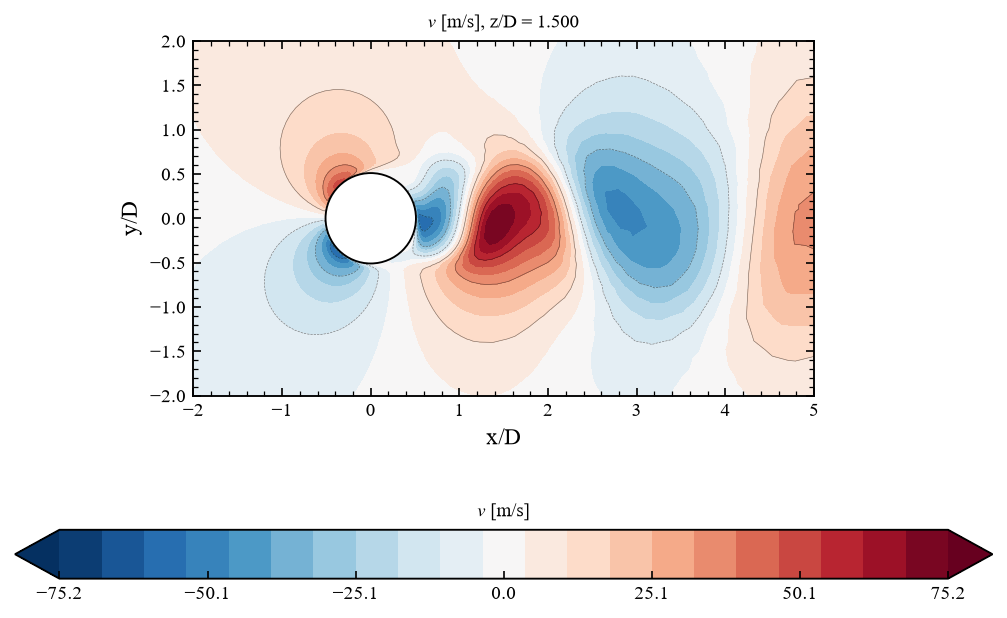

c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\v_section.png
$v$ [m/s]: -58.986 ... 75.168
section nodes in view = 3878, masked triangles = 98


In [8]:
X_LIM = (-2.0, 5.0)
Y_LIM = (-2.0, 2.0)
PAD = 0.45

in_box = (
    (x_sec > X_LIM[0] - PAD)
    & (x_sec < X_LIM[1] + PAD)
    & (y_sec > Y_LIM[0] - PAD)
    & (y_sec < Y_LIM[1] + PAD)
)
tri = mtri.Triangulation(x_sec[in_box], y_sec[in_box])
centers = np.column_stack(
    (x_sec[in_box][tri.triangles].mean(axis=1), y_sec[in_box][tri.triangles].mean(axis=1))
)
tri.set_mask(np.hypot(centers[:, 0], centers[:, 1]) < 0.5 * diam)


def plot_section(values, label, fname, n_levels=22, symmetric=False):
    local = values[in_box]
    if symmetric:
        vmax = float(np.abs(local).max())
        levels = np.linspace(-vmax, vmax, n_levels)
    else:
        levels = np.linspace(local.min(), local.max(), n_levels)
    fig, ax = plt.subplots(figsize=(6.6, 4.0), layout='constrained')
    filled = ax.tricontourf(tri, local, levels=levels, cmap=CMAP_FLOW, extend='both')
    ax.tricontour(tri, local, levels=levels[::3], colors='k', linewidths=0.3, alpha=0.5)
    ax.add_patch(
        plt.Circle((0.0, 0.0), 0.5 * diam, facecolor='white', edgecolor='k', linewidth=0.9, zorder=3)
    )
    ax.set_xlim(*X_LIM)
    ax.set_ylim(*Y_LIM)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('x/D')
    ax.set_ylabel('y/D')
    ax.set_title(f'{label}, z/D = {z_mid:.3f}')
    bar = fig.colorbar(filled, ax=ax, orientation='horizontal', pad=0.13, extend='both')
    bar.set_ticks(np.linspace(levels[0], levels[-1], 7))
    bar.ax.set_title(label)
    save_show(fig, fname)
    print(f'{label}: {local.min():.3f} ... {local.max():.3f}')


plot_section(u_sec, r'$u$ [m/s]', 'u_section.png')
plot_section(v_sec, r'$v$ [m/s]', 'v_section.png', symmetric=True)
print(f'section nodes in view = {int(in_box.sum())}, masked triangles = {int(tri.mask.sum())}')

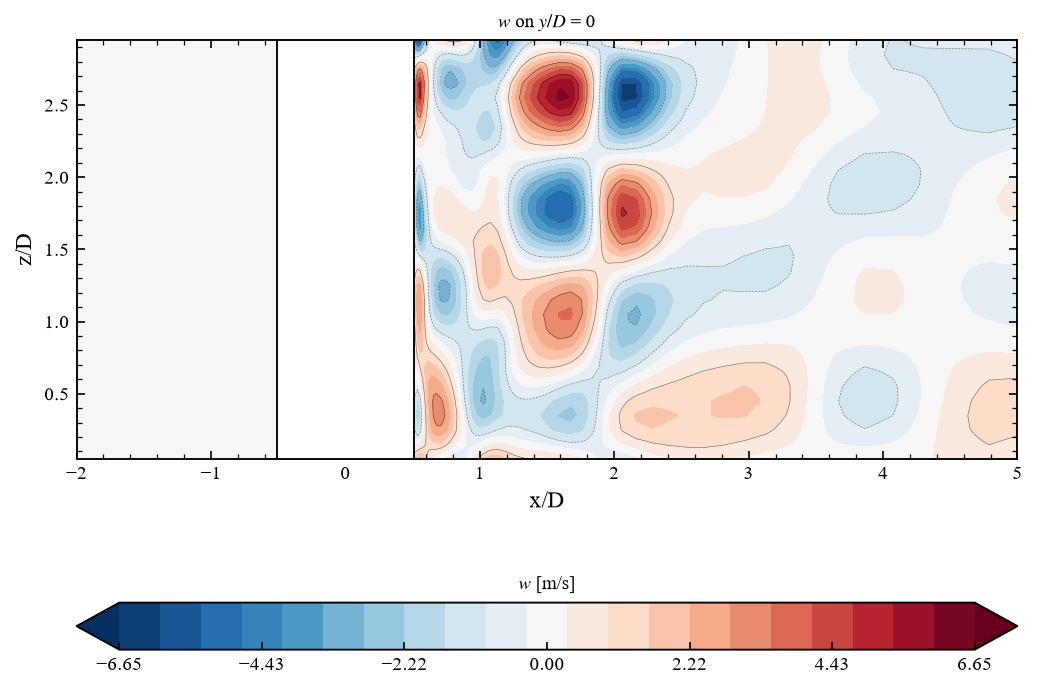

c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\w_top.png
slice points = 4800, x = -29.186 ... 29.186
spanwise w rms = 0.7812 m/s, |w|max = 6.6522 m/s
z/D      |w|max    w_rms
  0.05    4.454   0.403
  0.15    3.016   0.408
  0.25    4.336   0.604
  0.35    4.414   0.684
  0.45    3.697   0.627
  0.55    3.146   0.498
  0.65    3.349   0.405
  0.75    4.297   0.451
  0.85    5.564   0.607
  0.95    6.565   0.770
  1.05    6.830   0.874
  1.15    6.117   0.868
  1.25    4.756   0.718
  1.35    2.707   0.456
  1.45    3.146   0.358
  1.55    5.716   0.657
  1.65    8.319   0.963
  1.75    9.882   1.106
  1.85    9.556   1.052
  1.95    7.438   0.821
  2.05    4.088   0.477
  2.15    1.224   0.158
  2.25    4.714   0.429
  2.35    8.480   0.819
  2.45   11.174   1.151
  2.55   12.749   1.357
  2.65   11.866   1.359
  2.75    7.908   1.081
  2.85    6.257   0.677
  2.95    7.035   0.803


In [9]:
w_rows = []
for plane in z_planes:
    on_plane = np.isclose(zf, plane)
    w_plane = wf[on_plane].reshape(n_r, n_t)
    r_plane = rf[on_plane].reshape(n_r, n_t)[:, 0]
    w_front = 0.5 * (w_plane[:, 0] + w_plane[:, -1])
    w_back = 0.5 * (w_plane[:, n_t // 2 - 1] + w_plane[:, n_t // 2])
    w_rows.append(np.concatenate((w_back[::-1], w_front)))

w_slice = np.asarray(w_rows)
x_slice = np.concatenate((-r_plane[::-1], r_plane))

x_fine = np.linspace(X_LIM[0], X_LIM[1], 401)
z_fine = np.linspace(z_planes.min(), z_planes.max(), 241)
zz_fine, xx_fine = np.meshgrid(z_fine, x_fine, indexing='ij')
w_fine = RegularGridInterpolator((z_planes, x_slice), w_slice)(
    np.column_stack((zz_fine.ravel(), xx_fine.ravel()))
).reshape(zz_fine.shape)
w_max = float(np.abs(w_fine).max())
levels = np.linspace(-w_max, w_max, 22)
fig_h = float(np.clip(2.4 + 5.0 * np.ptp(z_planes) / (X_LIM[1] - X_LIM[0]), 2.6, 5.4))

fig, ax = plt.subplots(figsize=(6.8, fig_h), layout='constrained')
filled = ax.contourf(x_fine, z_fine, w_fine, levels=levels, cmap=CMAP_FLOW, extend='both')
ax.contour(x_fine, z_fine, w_fine, levels=levels[::3], colors='k', linewidths=0.3, alpha=0.5)
ax.add_patch(
    plt.Rectangle(
        (-0.5 * diam, z_planes.min()),
        diam,
        z_planes.max() - z_planes.min(),
        facecolor='white',
        edgecolor='k',
        linewidth=0.9,
        zorder=3,
    )
)
ax.set_xlim(*X_LIM)
ax.set_ylim(z_planes.min(), z_planes.max())
ax.set_xlabel('x/D')
ax.set_ylabel('z/D')
ax.set_title(r'$w$ on $y/D$ = 0')
bar = fig.colorbar(filled, ax=ax, orientation='horizontal', pad=0.13, extend='both')
bar.set_ticks(np.linspace(levels[0], levels[-1], 7))
bar.ax.set_title(r'$w$ [m/s]')
save_show(fig, 'w_top.png')

print(f'slice points = {w_slice.size}, x = {x_slice.min():.3f} ... {x_slice.max():.3f}')
print(f'spanwise w rms = {wf.std():.4f} m/s, |w|max = {w_max:.4f} m/s')
print('z/D      |w|max    w_rms')
for plane in z_planes:
    on_plane = np.isclose(zf, plane)
    print(f'  {plane:4.2f}  {np.abs(wf[on_plane]).max():7.3f}  {wf[on_plane].std():6.3f}')